# House Price Prediction — Bangladesh

Predict the sale price of a property (in taka) from its size, rooms, floor and location,
using ~2,800 unique listings from Dhaka, Chattogram, Narayanganj, Gazipur and Cumilla.

**Final model:** Extra Trees + Histogram Gradient Boosting, averaged, trained on log(price).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

## 1. Load the data

In [2]:
df = pd.read_csv("data/house_price_bd.csv")
print(len(df), "rows")
df.head()

3865 rows


,Title,Bedrooms,Bathrooms,Floor_no,Occupancy_status,Floor_area,City,Price_in_taka,Location
0,We Are Offering You A Very Spacious 1960 Sq Ft...,3.0,4.0,3,vacant,1960.0,dhaka,"৳39,000,000","Gulshan 1, Gulshan"
1,Valuable 1705 Square Feet Apartment Is Ready T...,3.0,3.0,1,vacant,1705.0,dhaka,"৳16,900,000","Lake Circus Road, Kalabagan"
2,1370 square feet apartment is ready to sale in...,3.0,3.0,6,vacant,1370.0,dhaka,"৳12,500,000","Shukrabad, Dhanmondi"
3,2125 Square Feet Apartment For Sale In Bashund...,3.0,3.0,4,vacant,2125.0,dhaka,"৳20,000,000","Block L, Bashundhara R-A"
4,Buy This 2687 Square Feet Flat In The Nice Are...,3.0,3.0,4,vacant,2687.0,dhaka,"৳47,500,000","Road No 25, Banani"


In [3]:
df.isna().sum()

Title                  0
Bedrooms            1001
Bathrooms           1001
Floor_no             684
Occupancy_status      99
Floor_area            99
City                   0
Price_in_taka          0
Location               6
dtype: int64

## 2. Clean the data

**Remove duplicate listings.** Many listings appear more than once with every column identical.
If copies of the same flat land in both the training and test sets, the model is graded on
flats it has already memorised and the score looks better than it really is.

In [4]:
print("duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print(len(df), "unique rows")

duplicate rows: 934
2931 unique rows


In [5]:
df["Price_in_taka"] = df["Price_in_taka"].str.replace("৳", "").str.replace(",", "").astype(float)
df["Floor_no"] = pd.to_numeric(df["Floor_no"], errors="coerce")
df["Occupancy_status"].value_counts(dropna=False)

Occupancy_status
vacant      2840
NaN           89
occupied       2
Name: count, dtype: int64

Almost every listing is `vacant`, so occupancy tells the model nothing. The title is free text, so we drop both.

Rows without a floor area or location can't be priced, so they go. Missing bedrooms, bathrooms
and floor number are **kept as missing**: they usually mean the listing is a plot or a shop,
and the tree models learn from that directly.

In [6]:
df = df.drop(columns=["Title", "Occupancy_status"])
df = df.dropna(subset=["Floor_area", "Location"])
df[["Bedrooms", "Bathrooms", "Floor_no"]].isna().mean().round(2)

Bedrooms     0.26
Bathrooms    0.26
Floor_no     0.18
dtype: float64

Keep the middle 98% of prices: the cheapest and most expensive 1% are mostly typos or unusual properties.

In [7]:
low, high = df["Price_in_taka"].quantile([0.01, 0.99])
df = df[(df["Price_in_taka"] >= low) & (df["Price_in_taka"] <= high)]
len(df)

2787

`Location` looks like `"Lake Circus Road, Kalabagan"`. The last part is the neighbourhood.

In [8]:
df["Area"] = df["Location"].str.split(",").str[-1].str.strip()
df["Area"].value_counts().head(10)

Area
Mirpur                        402
Narayanganj                   358
Gazipur Sadar Upazila         152
9 No. North Pahartali Ward    140
Bakalia                       129
Double Mooring                128
Bashundhara R-A               118
Bayazid                        99
4 No Chandgaon Ward            92
Uttara                         78
Name: count, dtype: int64

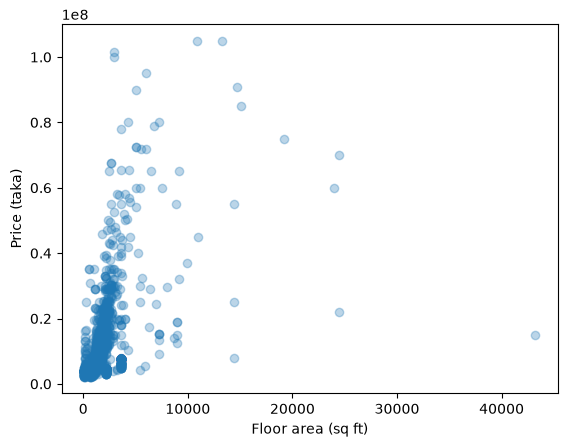

In [9]:
plt.scatter(df["Floor_area"], df["Price_in_taka"], alpha=0.3)
plt.xlabel("Floor area (sq ft)")
plt.ylabel("Price (taka)")
plt.show()

## 3. Features and train/test split

In [10]:
X = pd.get_dummies(df[["Bedrooms", "Bathrooms", "Floor_no", "Floor_area", "City", "Area"]], columns=["City", "Area"])
y = df["Price_in_taka"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train rows,", len(X_test), "test rows,", X.shape[1], "features")

2229 train rows, 558 test rows, 111 features


## 4. Models

Three numbers per model:
- **MAE**: average error in taka (lower is better)
- **MAPE**: average error as a % of the real price (lower is better)
- **R²**: how much of the price variation the model explains (1.0 is perfect)

In [11]:
results = {}

def evaluate(name, pred):
    results[name] = {
        "MAE (taka)": round(mean_absolute_error(y_test, pred)),
        "MAPE (%)": round(float(np.mean(np.abs(pred - y_test) / y_test) * 100), 1),
        "R2": round(r2_score(y_test, pred), 3),
    }
    print(name, results[name])

### Baselines

In [12]:
lin = LinearRegression().fit(X_train.fillna(X_train.median()), y_train)
evaluate("Linear Regression", lin.predict(X_test.fillna(X_train.median())))

rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
evaluate("Random Forest", rf.predict(X_test))

Linear Regression {'MAE (taka)': 2751225, 'MAPE (%)': 29.2, 'R2': 0.68}


Random Forest {'MAE (taka)': 1821263, 'MAPE (%)': 17.1, 'R2': 0.813}


### Improved model

Two changes help:
1. **Predict log(price)** instead of price. Prices range from about 2M to over 100M taka;
   on a log scale a 10% miss counts the same for a cheap flat and an expensive one.
2. **Average two different tree models.** Extra Trees and Gradient Boosting make different mistakes,
   so their average is more accurate than either one alone.

In [13]:
et = ExtraTreesRegressor(n_estimators=500, max_features=0.5, random_state=42, n_jobs=-1)
hgb = HistGradientBoostingRegressor(learning_rate=0.03, max_iter=800, min_samples_leaf=10, random_state=42)
et.fit(X_train, np.log(y_train))
hgb.fit(X_train, np.log(y_train))

def predict(X):
    return np.exp((et.predict(X) + hgb.predict(X)) / 2)

pred = predict(X_test)
evaluate("Extra Trees + Gradient Boosting", pred)

Extra Trees + Gradient Boosting {'MAE (taka)': 1745461, 'MAPE (%)': 15.8, 'R2': 0.84}


In [14]:
pd.DataFrame(results).T

,MAE (taka),MAPE (%),R2
Linear Regression,2751225.0,29.2,0.680
Random Forest,1821263.0,17.1,0.813
Extra Trees + Gradient Boosting,1745461.0,15.8,0.840


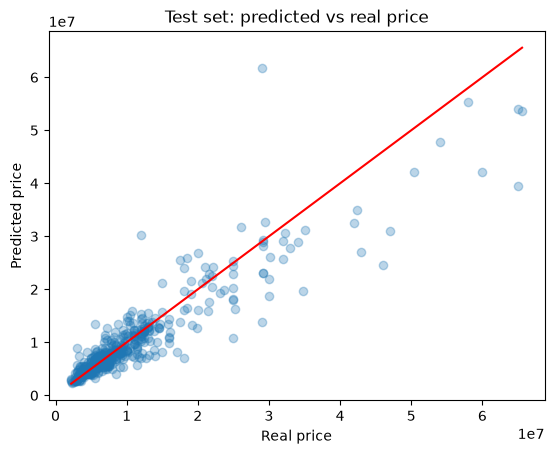

In [15]:
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Real price")
plt.ylabel("Predicted price")
plt.title("Test set: predicted vs real price")
plt.savefig("images/predictions.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Cross-validation

One test split can be lucky or unlucky. 5-fold cross-validation tests every row once
and gives a steadier score for comparing the baseline with the final model.

In [16]:
def cross_validate(make_models, log_target):
    pred = np.zeros(len(y))
    for train, test in KFold(5, shuffle=True, random_state=42).split(X):
        target = np.log(y.iloc[train]) if log_target else y.iloc[train]
        p = np.mean([m.fit(X.iloc[train], target).predict(X.iloc[test]) for m in make_models()], axis=0)
        pred[test] = np.exp(p) if log_target else p
    return {"MAE (taka)": round(mean_absolute_error(y, pred)),
            "MAPE (%)": round(float(np.mean(np.abs(pred - y) / y) * 100), 1),
            "R2": round(r2_score(y, pred), 3)}

cv = {
    "Random Forest": cross_validate(lambda: [RandomForestRegressor(300, random_state=42, n_jobs=-1)], log_target=False),
    "Extra Trees + Gradient Boosting": cross_validate(lambda: [
        ExtraTreesRegressor(500, max_features=0.5, random_state=42, n_jobs=-1),
        HistGradientBoostingRegressor(learning_rate=0.03, max_iter=800, min_samples_leaf=10, random_state=42),
    ], log_target=True),
}
pd.DataFrame(cv).T

,MAE (taka),MAPE (%),R2
Random Forest,1785545.0,16.2,0.800
Extra Trees + Gradient Boosting,1706133.0,15.1,0.821


## 6. Train on all data and save

In [17]:
et.fit(X, np.log(y))
hgb.fit(X, np.log(y))
joblib.dump({"et": et, "hgb": hgb, "columns": list(X.columns)}, "house_price_model.joblib", compress=3)

['house_price_model.joblib']

## 7. Predict a new flat

In [18]:
def predict_price(bedrooms, bathrooms, floor_no, floor_area, city, area):
    flat = pd.DataFrame([{"Bedrooms": bedrooms, "Bathrooms": bathrooms, "Floor_no": floor_no,
                          "Floor_area": floor_area, "City": city, "Area": area}])
    flat = pd.get_dummies(flat, columns=["City", "Area"]).reindex(columns=X.columns, fill_value=0)
    return predict(flat)[0]

print(f"3 bed, 1500 sq ft, 5th floor, Dhanmondi: ৳{predict_price(3, 3, 5, 1500, 'dhaka', 'Dhanmondi'):,.0f}")
print(f"3 bed, 1200 sq ft, 4th floor, Mirpur:    ৳{predict_price(3, 2, 4, 1200, 'dhaka', 'Mirpur'):,.0f}")

3 bed, 1500 sq ft, 5th floor, Dhanmondi: ৳16,127,543
3 bed, 1200 sq ft, 4th floor, Mirpur:    ৳7,251,013
